# nnscratch demo

Train a small feedforward network, built only with NumPy, on the 8x8 digits dataset that ships with scikit-learn. The demo covers the full pipeline: gradient check, training with Adam, convergence curves, and a look at some predictions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from nnscratch import (
    Adam,
    Dense,
    Dropout,
    ReLU,
    Sequential,
    SoftmaxCrossEntropy,
    accuracy,
    gradient_check,
    train,
)
from nnscratch.data import load_digits_data

x_train, x_test, y_train, y_test = load_digits_data(seed=0)
print(f"train {x_train.shape}, test {x_test.shape}")

train (1437, 64), test (360, 64)


## 1. Verify backpropagation with a numerical gradient check

Before trusting the training loop, compare the analytic gradients from backpropagation against central-difference estimates on a small network. The symmetric relative error should be far below 1e-5.

In [2]:
rng = np.random.default_rng(0)
check_model = Sequential([
    Dense(64, 16, init="he", l2=1e-3, rng=rng),
    ReLU(),
    Dense(16, 10, init="xavier", rng=rng),
])
rel_error = gradient_check(check_model, SoftmaxCrossEntropy(), x_train[:8], y_train[:8])
print(f"max relative error: {rel_error:.2e}")
assert rel_error < 1e-5

max relative error: 1.98e-09


## 2. Train a classifier with Adam

Two hidden ReLU layers with He initialization, light L2 weight decay, and dropout on the hidden activations.

In [3]:
rng = np.random.default_rng(0)
model = Sequential([
    Dense(64, 128, init="he", l2=1e-4, rng=rng),
    ReLU(),
    Dropout(0.1, rng=rng),
    Dense(128, 128, init="he", l2=1e-4, rng=rng),
    ReLU(),
    Dropout(0.1, rng=rng),
    Dense(128, 10, init="xavier", l2=1e-4, rng=rng),
])
history = train(
    model,
    Adam(lr=0.001),
    x_train,
    y_train,
    x_val=x_test,
    y_val=y_test,
    epochs=30,
    batch_size=64,
    rng=np.random.default_rng(0),
)
print(f"final test accuracy: {accuracy(model, x_test, y_test):.4f}")

final test accuracy: 0.9833


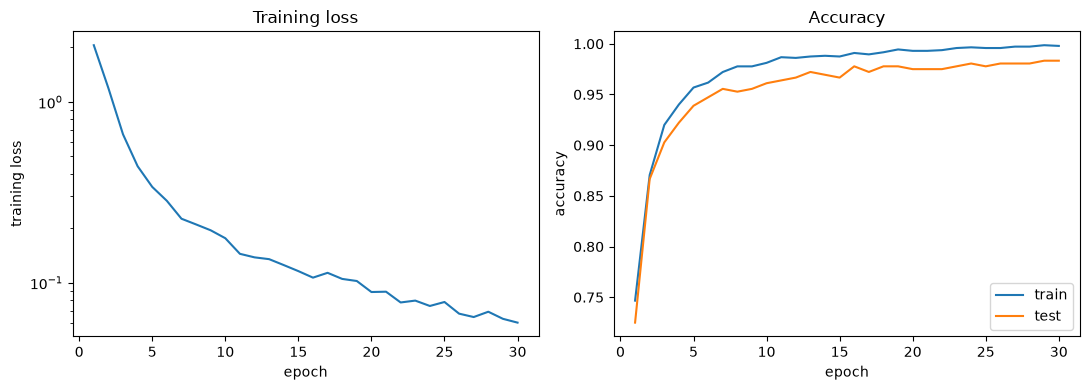

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
epochs = range(1, len(history.loss) + 1)
ax1.plot(epochs, history.loss)
ax1.set_xlabel("epoch")
ax1.set_ylabel("training loss")
ax1.set_yscale("log")
ax1.set_title("Training loss")
ax2.plot(epochs, history.train_accuracy, label="train")
ax2.plot(epochs, history.val_accuracy, label="test")
ax2.set_xlabel("epoch")
ax2.set_ylabel("accuracy")
ax2.set_title("Accuracy")
ax2.legend()
fig.tight_layout()
plt.show()

## 3. Inspect predictions

A quick look at test images with the predicted and true labels. Misclassified digits, if any appear in this sample, are marked in red.

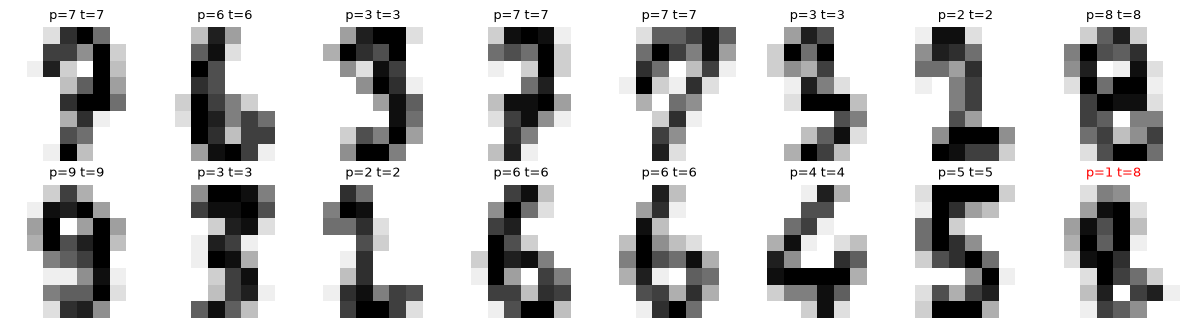

misclassified: 6 of 360 test samples


In [5]:
preds = model.predict(x_test)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i].reshape(8, 8), cmap="gray_r")
    correct = preds[i] == y_test[i]
    ax.set_title(f"p={preds[i]} t={y_test[i]}", color="black" if correct else "red", fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

n_wrong = int((preds != y_test).sum())
print(f"misclassified: {n_wrong} of {len(y_test)} test samples")